# Assignment 2 - Coding
### Andres Arias Medina
### Z23987588

## 10. (coding) PCA

In [39]:
import numpy as np                       
import pandas as pd                      
import matplotlib.pyplot as plt          

# read iris dataset
data = pd.read_csv('iris.csv', header=None)           # load the dataset from the CSV file

# X: input features
X = data.iloc[:, 0:4]                    # first 4 columns are the input features
# Y: target
Y = data.iloc[:, 4]                      # 5th column is the class label (species)

N = X.shape[0]                           # number of samples (rows)
print('Shape of X:', X.shape)            # show dimensions of the feature matrix
print(data.head())                       # show the first rows of the dataset

Shape of X: (150, 4)
     0    1    2    3            4
0  5.1  3.5  1.4  0.2  Iris-setosa
1  4.9  3.0  1.4  0.2  Iris-setosa
2  4.7  3.2  1.3  0.2  Iris-setosa
3  4.6  3.1  1.5  0.2  Iris-setosa
4  5.0  3.6  1.4  0.2  Iris-setosa


### 10.1 Covariance matrix, eigenvalues and eigenvectors

First center data by subtracting the mean of each feature, `X_centered = X - mean(X)`.
Then compute the covariance matrix

S = (1/N) Σ (xₙ − x̄)(xₙ − x̄)ᵀ, which in matrix form is S = X_centeredᵀ X_centered / N.

4×4 matrix with a diagonal that contains the variance of each feature and the off diagonal entries contain the covariances between pairs of features

In [40]:
X_mean = X.mean(axis=0)                  # mean of each feature
X_centered = X - X_mean                  # subtract the mean so every feature has mean 0
S = np.dot(X_centered.T, X_centered) / N # covariance matrix

print('Covariance matrix S:')         
print(np.round(S, 4))               

Covariance matrix S:
[[ 0.6811 -0.039   1.2652  0.5135]
 [-0.039   0.1868 -0.3196 -0.1172]
 [ 1.2652 -0.3196  3.0924  1.2877]
 [ 0.5135 -0.1172  1.2877  0.5785]]


**Eigenvalues and eigenvectors**

We use `np.linalg.eigh`, which is designed for symmetric matrices such as S.
It returns the eigenvalues in ascending order and the eigenvectors as the columns of a matrix

In [41]:
eig_vals, eig_vecs = np.linalg.eigh(S)   # eigen decomposition of the symmetric matrix S

print('All eigenvalues (ascending):')    
print(np.round(eig_vals, 4))             # each eigenvalue = variance along its eigenvector
print(' ')
print('All eigenvectors (columns):')     
print(np.round(eig_vecs, 4))             # column i is the eigenvector of eig_vals[i]

All eigenvalues (ascending):
[0.0235 0.078  0.2406 4.1967]
 
All eigenvectors (columns):
[[ 0.3173  0.581   0.6565 -0.3616]
 [-0.3241 -0.5964  0.7297  0.0823]
 [-0.4797 -0.0725 -0.1758 -0.8566]
 [ 0.7511 -0.5491 -0.0747 -0.3588]]


**Choose the two largest eigenvalues and their eigenvectors.**

We sort the eigenvalues in descending order with `np.argsort(...)[::-1]`, reorder the eigenvectors in the same way, and keep the first two columns.

`eigvec_set` is a 4×2 matrix whose columns are the first and second principal components (PC1 and PC2)

In [42]:
order = np.argsort(eig_vals)[::-1]       # indices that sort eigenvalues from largest to smallest
eig_vals_sorted = eig_vals[order]        # eigenvalues in descending order
eig_vecs_sorted = eig_vecs[:, order]     # eigenvectors reordered to match the eigenvalues

top2_vals = eig_vals_sorted[:2]          # the two largest eigenvalues
eigvec_set = eig_vecs_sorted[:, :2]      # eigvec_set: two eigen vectors (4x2 matrix)

print('Two largest eigenvalues:', np.round(top2_vals, 4))          # lambda_1 and lambda_2
print('Corresponding eigenvectors (columns = PC1, PC2):')         
print(np.round(eigvec_set, 4))                                    # u1 and u2 as columns
print('Explained variance ratio:', np.round(top2_vals / eig_vals.sum(), 4))  # share of total variance
print('Total explained by PC1 + PC2:', round(top2_vals.sum() / eig_vals.sum(), 4))  # cumulative share

Two largest eigenvalues: [4.1967 0.2406]
Corresponding eigenvectors (columns = PC1, PC2):
[[-0.3616  0.6565]
 [ 0.0823  0.7297]
 [-0.8566 -0.1758]
 [-0.3588 -0.0747]]
Explained variance ratio: [0.9246 0.053 ]
Total explained by PC1 + PC2: 0.9776


**Projection (given code)**

Each sample is projected onto the two principal components: `pca_X = (eigvec_setᵀ Xᵀ)ᵀ`, every row xₙ becomes (u₁ᵀxₙ, u₂ᵀxₙ).
The dimension is reduced from 4 to 2

In [43]:
# compute projected data pca_X (dimension reduced from 4 to 2)
pca_X = np.dot(eigvec_set.transpose(), X.transpose()).transpose()  # project every sample onto PC1 and PC2
print('Shape of pca_X:', pca_X.shape)

Shape of pca_X: (150, 2)


### 10.1-2 Plot pca_X in 2D (x axis: PC1, y axis: PC2)

I draw a scatter plot of the projected data with PC1 on the x axis and PC2 on the y axis
Each species gets its own color so can see how well the 2D projection separates the classes

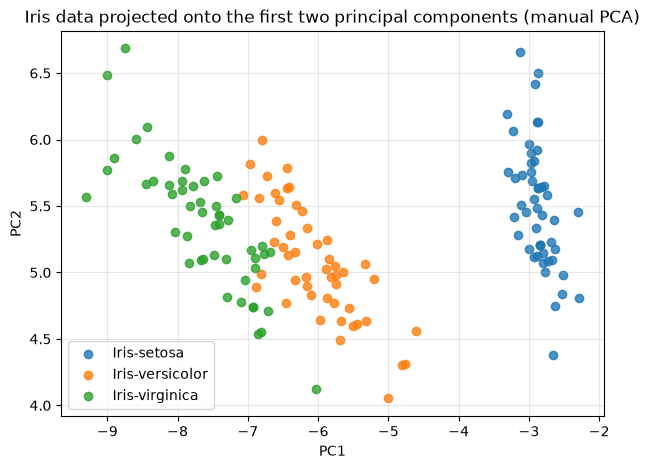

In [44]:
plt.figure(figsize=(7, 5))                         
for species in Y.unique():                          # loop over the 3 iris species
    mask = (Y == species).values                    # boolean mask for the samples of this species
    plt.scatter(pca_X[mask, 0], pca_X[mask, 1],     # PC1 on x axis, PC2 on y axis
                label=species, alpha=0.8)          
plt.xlabel('PC1')                                   
plt.ylabel('PC2')                                  
plt.title('Iris data projected onto the first two principal components (manual PCA)')  
plt.legend()                                        
plt.grid(alpha=0.3)                                 # light grid for readability
plt.show()                                          

**Observation** 

PC1 alone explains most of the variance (about 92%) and clearly separates setosa from the other two species, versicolor and virginica overlap slightly but are mostly separated along PC1

### 10.2 PCA with sklearn and comparison with 10. 1

Repeat the dimensionality reduction with `sklearn.decomposition.PCA(n_components=2)`
Then compare it with our manual implementation
1. **Components:** `pca.components_` should match our eigenvectors, possibly with the opposite sign (an eigenvector and its negative define the same direction).
2. **Eigenvalues:** `pca.explained_variance_` uses the 1/(N−1) convention, so it equals our eigenvalues multiplied by N/(N−1). The explained variance ratios must be identical.
3. **Projected data:** sklearn centers the data before projecting, while the given code projects the raw X. Therefore the two projections differ only by a constant shift (and possibly a sign flip), so they have the same shape on the plot.

In [45]:
from sklearn.decomposition import PCA            

pca = PCA(n_components=2)                         # keep 2 principal components (4 -> 2)
sk_X = pca.fit_transform(X)                       # fit PCA on X and project the data

print('sklearn components (rows = PC1, PC2)')    
print(np.round(pca.components_, 4))               # principal directions found by sklearn
print('Our eigenvectors (transposed)')       
print(np.round(eigvec_set.T, 4))                  # our principal directions for comparison

sklearn components (rows = PC1, PC2)
[[ 0.3616 -0.0823  0.8566  0.3588]
 [ 0.6565  0.7297 -0.1758 -0.0747]]
Our eigenvectors (transposed)
[[-0.3616  0.0823 -0.8566 -0.3588]
 [ 0.6565  0.7297 -0.1758 -0.0747]]


In [46]:
print('sklearn explained_variance_ :', np.round(pca.explained_variance_, 4))       # uses 1/(N-1)
print('Our eigenvalues * N/(N-1)   :', np.round(top2_vals * N / (N - 1), 4))       # convert our 1/N values
print('sklearn explained ratio     :', np.round(pca.explained_variance_ratio_, 4)) # share of variance (sklearn)
print('Our explained ratio         :', np.round(top2_vals / eig_vals.sum(), 4))    # share of variance (ours)

signs = np.sign(np.sum(pca.components_ * eigvec_set.T, axis=1))  # +1 if same direction, -1 if flipped
print('Same direction (+1) or flipped (-1):', signs)             # report the sign of each component

sklearn explained_variance_ : [4.2248 0.2422]
Our eigenvalues * N/(N-1)   : [4.2248 0.2422]
sklearn explained ratio     : [0.9246 0.053 ]
Our explained ratio         : [0.9246 0.053 ]
Same direction (+1) or flipped (-1): [-1.  1.]


### I used AI to create the following cell

Max absolute difference after centering and sign alignment: 6.217248937900877e-15


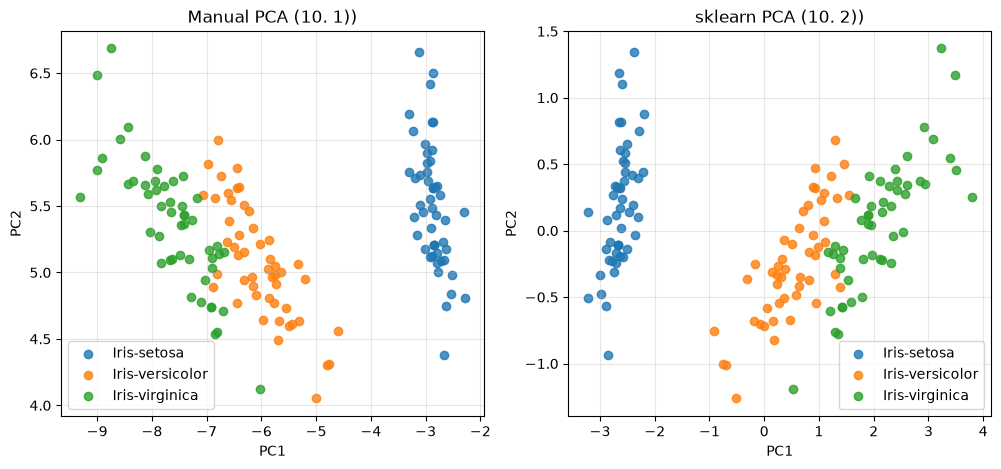

In [47]:
ours_centered = pca_X - pca_X.mean(axis=0)              # remove the constant shift from our projection
ours_aligned = ours_centered * signs                     # flip our axes to match sklearn's signs
print('Max absolute difference after centering and sign alignment:',
      np.abs(ours_aligned - sk_X).max())                 # should be ~0 (numerical precision)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))            # two plots side by side
for species in Y.unique():                               # loop over species
    mask = (Y == species).values                         # samples of this species
    ax[0].scatter(pca_X[mask, 0], pca_X[mask, 1], label=species, alpha=0.8)  # manual PCA
    ax[1].scatter(sk_X[mask, 0], sk_X[mask, 1], label=species, alpha=0.8)    # sklearn PCA
ax[0].set_title('Manual PCA (10. 1))')                   # title of left plot
ax[1].set_title('sklearn PCA (10. 2))')                  # title of right plot
for a in ax:                                             # format both plots
    a.set_xlabel('PC1'); a.set_ylabel('PC2'); a.legend(); a.grid(alpha=0.3)  # labels, legend, grid
plt.show()                                               # display both plots

**Comparison** 

Both methods find the same two principal directions (up to the sign of each eigenvector) and the same explained variance ratios (0.9246 and 0.0531). sklearn's explained_variance_ differs from our eigenvalues only by the factor N/(N−1), because sklearn divides by N−1 while method of class divide by N. 

The two scatter plots have the same shape, the only differences are a translation (sklearn centers the data before projecting) and a possible reflection of an axis (sign of the eigenvector), which do not change the relative positions of the points.

## 11. (coding) (Multinomial) Naïve Bayes

In [48]:
import numpy as np                       

class MultinomialNaiveBayes:            
    def __init__(self, alpha=1.0):      
        self.alpha = alpha               # Laplace smoothing (alpha = 1)

### 11.1 Number of samples, features and classes

- `n_samples`: number of rows of X (training documents).
- `n_features`: number of columns of X (words in the vocabulary; each value is a word count).
- `self.classes`: the distinct class labels, obtained with `np.unique(y)` (sorted alphabetically: `['ham', 'spam']`).
- `n_classes`: how many distinct classes there are.

In [49]:
def compute_sizes(self, X, y):
    n_samples, n_features = X.shape      # rows = samples, columns = features
    self.classes = np.unique(y)          # distinct class labels (sorted)
    n_classes = len(self.classes)        # number of distinct classes
    return n_samples, n_features, n_classes  

### 11. 2 Subset of X for class c and smoothed log prior

1. `X_c = X[y == c]` keeps only the training samples whose label is c.
2. The prior is estimated with smoothing (slide p.26):

   P(Y = c) = (#{Y = c} + α) / (|D| + αK),

   where #{Y = c} is the number of samples of class c, |D| = n_samples and K = n_classes.
   We store its **log** in `self.class_log_prior[idx]`, because summing logs avoids numerical underflow when many small probabilities are multiplied (slide p.22).

In [50]:
def compute_class_prior(self, X, y, c, idx, n_samples, n_classes):
    X_c = X[y == c]                                          # samples that belong to class c
    prior = (X_c.shape[0] + self.alpha) / (n_samples + self.alpha * n_classes)  # smoothed prior (p.26)
    self.class_log_prior[idx] = np.log(prior)                # store log P(Y = c)
    return X_c                                               

### 11. 3 Smoothed feature probabilities θ̂

For multinomial naive Bayes, θ̂ᵢₖ is the probability that a word occurrence in class k is word i:

θ̂ᵢₖ = (count of feature i in class k + α) / (total count of all features in class k + α·n_features)

- Numerator: `X_c.sum(axis=0)` adds the counts of each word over all samples of class c, plus α.
- Denominator: `X_c.sum()` is the total number of word occurrences in class c, plus α times the number of features (the number of possible values, J in slide p.25), so that the probabilities of each class sum to 1.
- Smoothing prevents zero probabilities for words never seen in a class (slide p.25).
- We take the log and store it in `self.feature_log_prob[idx]`.

In [51]:
def compute_feature_prob(self, X_c, idx, n_features):
    feature_counts = X_c.sum(axis=0)                         # total count of each feature in class c
    total_count = X_c.sum()                                  # total count of all features in class c
    theta = (feature_counts + self.alpha) / (total_count + self.alpha * n_features)  # smoothed P(x_i | c)
    self.feature_log_prob[idx] = np.log(theta)               # store log probabilities for class c

### fit(): training using the functions above
This is the fit method of the template. It calls 11.1 once, creates the arrays for the log priors and log feature probabilities and then loops over each class calling 11.2 and 11.3

In [52]:
def fit(self, X, y):
    n_samples, n_features, n_classes = compute_sizes(self, X, y)   # 11. 1

    self.class_log_prior = np.zeros(n_classes)                     # one log prior per class
    self.feature_log_prob = np.zeros((n_classes, n_features))      # one row of log probs per class

    for idx, c in enumerate(self.classes):                         # loop over every class
        X_c = compute_class_prior(self, X, y, c, idx, n_samples, n_classes)  # 11. 2
        compute_feature_prob(self, X_c, idx, n_features)           # 11.3
    return self                                                    # return the trained model

MultinomialNaiveBayes.fit = fit                                    # attach fit to the class

### 11.4 predict() log probability of each class and predicted labels

For each sample x and class k we compute the score following course slides

log P(Y = k) + Σᵢ xᵢ · log P(featureᵢ | Y = k)

In matrix form, for all samples at once: `X @ self.feature_log_prob.T + self.class_log_prior`, which gives an (n_samples × n_classes) matrix.
P(x) is not needed because it is the same for all classes. We take the `argmax` over classes and return the corresponding labels.

In [53]:
def predict(self, X):
    log_probs = X @ self.feature_log_prob.T + self.class_log_prior   # score of every class for every sample
    best = np.argmax(log_probs, axis=1)                              # index of the highest score per sample
    return self.classes[best]                                        # convert indices to class labels

MultinomialNaiveBayes.predict = predict                              

### Example usage, simple spam/ham text classification
Features are word counts. The first two training samples (spam) use words 1 and 2, the last two (ham) use words 3 to 5.
I trained the model and predict two test samples

In [54]:
# Simple spam/ham text classification
X_train = np.array([
    [2, 1, 0, 0, 0], [3, 2, 0, 0, 0], [0, 0, 2, 1, 1], [0, 0, 1, 2, 2], ])   # word counts per email
y_train = np.array(["spam", "spam", "ham", "ham"])                         # labels
X_test = np.array([
    [2, 1, 0, 0, 0], [0, 0, 1, 1, 1], ])                                   # two new emails

model = MultinomialNaiveBayes(alpha=1.0)        # create the model with Laplace smoothing
model.fit(X_train, y_train)                     # train on the example data
predictions = model.predict(X_test)             # predict the test emails
print("Predictions:", predictions)              # expected: ['spam' 'ham']

Predictions: ['spam' 'ham']


### Check, learned parameters and comparison with sklearn
Print the learned priors and feature probabilities and compare the predictions with sklearn.naive_bayes.MultinomialNB(alpha=1.0)

In [55]:
from sklearn.naive_bayes import MultinomialNB      # reference implementation

print('Classes:', model.classes)                                 # class order used in the arrays
print('P(class):', np.round(np.exp(model.class_log_prior), 4))   # smoothed priors
print('P(feature | class):')                                     # label for the output
print(np.round(np.exp(model.feature_log_prob), 4))               # smoothed feature probabilities

sk = MultinomialNB(alpha=1.0).fit(X_train, y_train)              # train sklearn's version
print('sklearn predictions:', sk.predict(X_test))                # should match our predictions
print('Same feature probabilities as sklearn:',
      np.allclose(model.feature_log_prob, sk.feature_log_prob_)) # compare theta estimates

Classes: ['ham' 'spam']
P(class): [0.5 0.5]
P(feature | class):
[[0.0714 0.0714 0.2857 0.2857 0.2857]
 [0.4615 0.3077 0.0769 0.0769 0.0769]]
sklearn predictions: ['spam' 'ham']
Same feature probabilities as sklearn: True
